# Module 1 — Task 3: Financial decision

**Brief (verbatim):**
> **Task 3: Financial decision**
> Students should calculate an approximate project NPV and expected NPV and final decision classifying as whether to fund (High expected value and acceptable risk), review (Potentially attractive but significant uncertainty) and reject (Low expected value or excessive risk).
> Expected NPV = P(Success) × NPV

**Where this sits in the chain:** Data → ML Prediction → **Financial Metric → Risk Assessment → Business Decision**.
- Task 1 checked the data, and Task 2 produced P(Success), the predicted probability that each initiative succeeds.
- Here the ML prediction **becomes an input** to the financial metric (Expected NPV = P × NPV).
- Finance and risk checks then decide Fund / Review / Reject.

**How this notebook is laid out:** each step has a plain explanation (with formulas), then the commented code, then its table or chart.

| Step | What it does |
| --- | --- |
| 0 | Setup |
| 1 | Load the data and Task 2's P(Success) |
| 2 | NPV and Expected NPV |
| 3 | Break-even life and the hurdle check |
| 4 | The decision rule: Fund / Review / Reject, with a reason for every initiative |
| 5 | Loss tolerance and the funding condition |
| 6 | Priority order within each label |
| 7 | Results in ₹ |
| 7b | Decisions by business unit and risk level |
| 8 | Sensitivity 1: where P(Success) comes from (what the ML adds) |
| 9 | Sensitivity 2: the break-even cut-off |
| 10 | Board view and hand-off to Module 9 |
| 10b | The Board decision file: every check, in words |
| 11 | Save the outputs |
| 12 | What the results say: the finance case, the ML case, and the decision |

**Decisions used** (all in `docs/decisions.md`):
- M1-02: discount rate = the row's Interest_Rate;
- M1-03: 3 years of cash flow;
- M1-04: break-even life;
- M1-05: hurdle;
- **M1-06: the decision rule, points A–F;**
- M1-20 and M1-23: sensitivity on P(Success).

**Runs on its own or from `run_module_1.ipynb`.** It reads Task 2's result file `outputs/task2/FINAL_M1_T2_success_probability.csv` (project rule P-15: tasks share results through files), so run Task 2 once before it.

**Helpers used:**
- `helpers/m01_data.py`: data plus derived columns, including NPV;
- `helpers/m01_finance.py`: cash flows, discount rate, break-even life, hurdle;
- `helpers/m01_style.py`: chart style.

The decision rule itself is written out in this notebook (step 4), so it can be read where it is applied.

## 0. Setup

Works locally and in Google Colab.
- **Colab:** upload the whole unzipped project folder (any name) to Google Drive; the cell below finds it. Then run all cells.
- The notebook runs in a few seconds.

In [1]:
import sys
import json
import warnings
from pathlib import Path

# ---- Find the project folder: any folder name works, on your computer or in Google Colab ----
# The project folder is the one holding run_novafin.ipynb and data/.
IN_COLAB = "google.colab" in sys.modules
is_project = lambda p: (p / "run_novafin.ipynb").exists() and (p / "data").is_dir()
places = [p for p in [Path.cwd(), *Path.cwd().parents] if is_project(p)]
if IN_COLAB and not places:                                 # Colab starts outside the project: look in /content, then in Google Drive
    for base in [Path("/content"), Path("/content/drive/MyDrive")]:
        if "drive" in base.parts:
            from google.colab import drive
            drive.mount("/content/drive")                   # asks for access to your Google Drive
        for depth in ["", "*/", "*/*/", "*/*/*/"]:
            places += [f.parent for f in sorted(base.glob(depth + "run_novafin.ipynb")) if is_project(f.parent)]
        if places:
            break
if not places:
    raise FileNotFoundError("Project folder not found: unzip the whole project and keep run_novafin.ipynb, data/ and the module folders together (see HOW_TO_RUN.md).")
PROJECT_ROOT = places[0]

MODULE_DIR = PROJECT_ROOT / "module_01_corporate_finance"
OUT_DIR = MODULE_DIR / "outputs" / "task3"            # decision table, summaries, charts
OUT_DIR.mkdir(parents=True, exist_ok=True)
TASK2_FILE = MODULE_DIR / "outputs" / "task2" / "FINAL_M1_T2_success_probability.csv"   # Task 2's result (P-15)
sys.path.insert(0, str(MODULE_DIR / "helpers"))       # make the Module 1 helpers importable
warnings.filterwarnings("ignore", category=FutureWarning)

# ---- Libraries ---------------------------------------------------------------------------
import numpy as np                    # maths on arrays
import pandas as pd                   # tables
import matplotlib.pyplot as plt       # charts

# ---- Module 1 helpers --------------------------------------------------------------------
from m01_data import load_initiatives_with_features
from m01_finance import break_even_years, hurdle_pass
from m01_style import apply_style, INK, INK_2, GRID, BLUE, ORANGE, AQUA
apply_style()
plt.close("all")                      # when run from the runner, close charts left open by Task 2 so they are not shown again here
pd.set_option("display.width", 220, "display.max_columns", 30)

# ---- The agreed settings of the decision rule (decision M1-06) ---------------------------
REVIEW_YEARS = 5                      # point D: slow payers must break even within 5 years
LABEL_COLOURS = {"Fund": BLUE, "Review": AQUA, "Reject": ORANGE}   # same colour per label in every chart


def save_table(table: pd.DataFrame, name: str, keep_index: bool = False) -> None:
    """Save a table to outputs/task3/<name>.csv."""
    table.to_csv(OUT_DIR / f"{name}.csv", index=keep_index)


def save_chart(fig, name: str) -> None:
    """Save a chart to outputs/task3/<name>.png at print quality."""
    fig.savefig(OUT_DIR / f"{name}.png", dpi=150, bbox_inches="tight")


print("Project folder found")
print("Outputs go to: ", OUT_DIR.relative_to(PROJECT_ROOT).as_posix())

Project folder found
Outputs go to:  module_01_corporate_finance/outputs/task3


## 1. Load the data and Task 2's P(Success)

- **Data:** the 180 initiatives with the derived columns from the shared helper (cash flows CF1–CF3, NPV_3yr, ROI_Spread, …), exactly as in Tasks 1 and 2.
- **P(Success):** lasso's **out-of-fold** probability for each initiative, from `outputs/task2/FINAL_M1_T2_success_probability.csv`.
  - Out-of-fold means each probability came from a model that never saw that initiative (Task 2, step 2), so it is an honest estimate.
  - The file also carries `At_Risk` = 1 when P(Success) is below the base rate.
- **Base rate** = successes ÷ initiatives = 138 ÷ 180 = 0.767. It is the "at risk" line in Task 2, and the P(Success) gate here (point C).

In [2]:
# Stop with a clear message if Task 2 has not been run yet (this notebook needs its result file).
if not TASK2_FILE.exists():
    raise FileNotFoundError(f"{TASK2_FILE} not found. Run notebooks/m01_task2_model.ipynb first "
                            "(or Run all in run_module_1.ipynb).")

df = load_initiatives_with_features()                         # 180 rows, given + derived columns
p_file = pd.read_csv(TASK2_FILE)                              # Initiative_ID, P_Success, At_Risk, Model
df = df.merge(p_file[["Initiative_ID", "P_Success", "At_Risk"]], on="Initiative_ID", how="left", validate="1:1")
assert df["P_Success"].notna().all(), "every initiative must have a P(Success) from Task 2"

df["Risk_Rating"] = df["Risk_Rating"].astype(str)             # plain text: Low / Medium / High
BASE_RATE = df["Historical_Success"].mean()                   # 0.767, the "at risk" line (same as Task 2)

print(f"{len(df)} initiatives; P(Success) from Task 2 model: {p_file['Model'].iloc[0]}")
print(f"P(Success) range {df.P_Success.min():.3f}–{df.P_Success.max():.3f}; base rate {BASE_RATE:.3f}; "
      f"flagged at risk: {int(df.At_Risk.sum())}")
display(df[["Initiative_ID", "Business_Unit", "Risk_Rating", "Initial_Investment", "P_Success", "At_Risk"]].head())

180 initiatives; P(Success) from Task 2 model: Lasso
P(Success) range 0.557–0.895; base rate 0.767; flagged at risk: 106


,Initiative_ID,Business_Unit,Risk_Rating,Initial_Investment,P_Success,At_Risk
0,1001,SME Lending,Medium,131.13,0.6612,1
1,1002,SME Lending,Medium,286.69,0.7535,1
2,1003,Wealth,High,227.64,0.7346,1
3,1004,Digital Banking,Medium,191.64,0.6590,1
4,1005,Corporate Banking,Medium,72.13,0.6691,1


## 2. NPV and Expected NPV

**Cash flow** in year t is what the initiative brings in that year, after its yearly operating cost (decision M1-01):

```text
CFt = Revenue_Year t − Operating_Cost
```

**NPV (Net Present Value)** is today's value of the cash an initiative brings in, minus what it costs.
- Future cash is worth less than cash today, because today's money could earn interest meanwhile. So each year's cash is **discounted** by the cost of money.
- Here that is the row's own Interest_Rate (M1-02), over the 3 years the data covers (M1-03):

```text
r   = Interest_Rate ÷ 100
NPV = −Initial_Investment + CF1 ÷ (1 + r) + CF2 ÷ (1 + r)² + CF3 ÷ (1 + r)³        (₹ lakh)
```

**Expected NPV**, the brief's formula, weights the value by the chance of success:

```text
Expected NPV = P(Success) × NPV
```

**Worked example, initiative 1075** (Wealth, Low risk):
- NPV = +55.57;
- P = 0.867;
- Expected NPV = 0.867 × 55.57 = +48.2 lakh.

**Two properties to keep in mind:**
1. P is always above 0, so Expected NPV has **the same sign as NPV**. P can scale value, but cannot turn a loss into a gain.
2. For a negative NPV, a *higher* P makes Expected NPV *more* negative. Expected NPV is therefore not used to rank loss-making projects (point F).

In [3]:
# NPV_3yr is already computed row by row by the shared helper (same formula as above).
df["Expected_NPV"] = df["P_Success"] * df["NPV_3yr"]          # brief's formula, ₹ lakh

summary = pd.DataFrame({
    "Initiatives": [len(df), int((df.NPV_3yr > 0).sum()), int((df.NPV_3yr <= 0).sum())],
    "Total NPV (₹ lakh)": [df.NPV_3yr.sum(), df.NPV_3yr[df.NPV_3yr > 0].sum(), df.NPV_3yr[df.NPV_3yr <= 0].sum()],
    "Total Expected NPV (₹ lakh)": [df.Expected_NPV.sum(), df.Expected_NPV[df.NPV_3yr > 0].sum(),
                                    df.Expected_NPV[df.NPV_3yr <= 0].sum()],
}, index=["All", "NPV > 0", "NPV ≤ 0"]).round(1)
display(summary)
print("Initiatives with positive NPV (the only ones with positive Expected NPV):")
display(df.loc[df.NPV_3yr > 0, ["Initiative_ID", "Business_Unit", "Risk_Rating", "Initial_Investment",
                                "NPV_3yr", "P_Success", "Expected_NPV"]]
          .sort_values("Expected_NPV", ascending=False).round(2))

,Initiatives,Total NPV (₹ lakh),Total Expected NPV (₹ lakh)
All,180,-13353.3,-9881.6
NPV > 0,8,225.0,170.2
NPV ≤ 0,172,-13578.3,-10051.9


Initiatives with positive NPV (the only ones with positive Expected NPV):


,Initiative_ID,Business_Unit,Risk_Rating,Initial_Investment,NPV_3yr,P_Success,Expected_NPV
74,1075,Wealth,Low,220.85,55.57,0.87,48.19
30,1031,Wealth,Medium,194.04,53.69,0.75,40.05
2,1003,Wealth,High,227.64,37.74,0.73,27.72
178,1179,Digital Banking,High,282.92,28.61,0.71,20.31
153,1154,Wealth,Medium,162.15,31.34,0.64,20.20
61,1062,Corporate Banking,Low,103.26,9.86,0.79,7.81
73,1074,Corporate Banking,Medium,250.17,6.32,0.74,4.71
114,1115,SME Lending,High,201.02,1.91,0.65,1.25


## 3. Break-even life and the hurdle check

Only 8 of 180 initiatives repay their investment within the 3 years of data. Two finance measures tell the **slow payers** (good projects that need a little longer) from projects that never pay back.

**Break-even life** (M1-04): how many years of cash flow it takes for NPV to reach 0.
- Years 1–3 use the data; after that we repeat the year-3 cash flow, each year discounted.
- It is a **measurement** of how much a project relies on cash after the data ends, not a forecast.

```text
Break-even life = smallest N where  −Investment + Σ (t = 1 … N) CFt ÷ (1 + r)^t  ≥ 0,   with CFt = CF3 for t > 3
"Never" if it doesn't pay back within 30 years (e.g. the year-3 cash flow is not positive)
```

Example (1002): NPV after 3 years is −169.9. Adding its year-3 cash flow of 60.04 each year, discounted, reaches 0 in **year 8**.

**Hurdle check** (M1-05): does the promised yearly return beat the yearly cost of money?

```text
Passes the hurdle  ⇔  Expected_ROI > Interest_Rate        (both in % a year)
```

In [4]:
df["Break_Even_Years"] = break_even_years(df)                  # NaN = never within 30 years (helper, M1-04)
df["Passes_Hurdle"] = hurdle_pass(df)                          # True / False (helper, M1-05)

be_table = (df["Break_Even_Years"].fillna(0).astype(int).replace(0, -1)
              .map(lambda v: "never" if v == -1 else ("11+" if v > 10 else str(v)))
              .value_counts().reindex(["3", "4", "5", "6", "7", "8", "9", "10", "11+", "never"], fill_value=0))
print(f"Median break-even life: {df.Break_Even_Years.median():.0f} years; "
      f"never break even: {int(df.Break_Even_Years.isna().sum())}; passes the hurdle: {int(df.Passes_Hurdle.sum())} of {len(df)}")
display(be_table.to_frame("Initiatives").T)

Median break-even life: 5 years; never break even: 17; passes the hurdle: 135 of 180


Break_Even_Years,3,4,5,6,7,8,9,10,11+,never
Initiatives,8,32,44,26,18,8,7,4,16,17


## 4. The decision rule: Fund / Review / Reject (decision M1-06, points A–D)

The brief defines the three labels in words. We turned them into a **gate rule** (point A): each initiative passes a few yes/no checks in order.

```text
Step 1  Does it create value in 3 years?   NPV > 0  (so Expected NPV > 0)
          ├─ yes, and Risk_Rating = Low            →  FUND    "High expected value and acceptable risk"     (point B)
          └─ yes, but Medium or High risk          →  REVIEW  "attractive but significant uncertainty": the risk
Step 2  If not: is it a slow payer worth a second look?
          break-even ≤ 5 years            (point D)
          AND passes the hurdle           (M1-05)
          AND not flagged "at risk"       (P(Success) ≥ base rate 0.767, point C)
          ├─ all yes                               →  REVIEW  "attractive but significant uncertainty": payback after year 3
          └─ any no                                →  REJECT  "Low expected value or excessive risk"
```

**Why each point:**

| Point | Choice | Reason in one line |
| --- | --- | --- |
| A | Gate rule | Each label traces to one phrase of the brief, and every decision can be explained in one line |
| B | Fund needs **Low** risk | Medium fails as often as High (69% vs 70%) and loses as much capital (30% vs 32%). Low: 89% and 9% |
| C | Slow payers need P ≥ 0.767 | The same "at risk" line as Task 2. Review is a closer look, so a wrong pass costs reviewer time, not capital |
| D | Break-even within 5 years | Only 2 years of assumed cash beyond the data; the median break-even life |

**Every initiative gets a reason.** For rejections, the first failing check is given, in this order:
1. never breaks even;
2. breaks even only after 5 years;
3. fails the hurdle;
4. flagged at risk by the model.

The rule is written as a function, so the sensitivity steps (8, 9) can rerun it with a different P(Success) or cut-off.

In [5]:
def decide(table: pd.DataFrame, p_success: pd.Series, review_years: int = REVIEW_YEARS,
           gate: float = None) -> pd.DataFrame:
    """Apply the agreed Fund / Review / Reject rule (M1-06, points A–D) to every initiative.

    table        : the initiatives, with NPV_3yr, Risk_Rating, Break_Even_Years, Passes_Hurdle
    p_success    : P(Success) per initiative (Task 2 model, or a sensitivity alternative)
    review_years : break-even cut-off for slow payers (point D, 5 years)
    gate         : P(Success) needed for a slow payer to reach Review (point C; default: base rate)
    Returns a table with Label, Review_Group, Reason_Code and Reason (one line per initiative).
    """
    gate = BASE_RATE if gate is None else gate
    npv = table["NPV_3yr"]
    exp_npv = p_success * npv                                  # Expected NPV (brief's formula)
    low = table["Risk_Rating"] == "Low"
    be = table["Break_Even_Years"]                             # NaN = never
    at_risk = p_success < gate                                 # the model's "at risk" flag

    # ---- Step 1: positive value ------------------------------------------------------------
    fund = (exp_npv > 0) & low                                 # point B: only Low risk is acceptable
    review_risk = (exp_npv > 0) & ~low                         # positive value, but Medium / High risk
    # ---- Step 2: slow payers (negative NPV) ---------------------------------------------------
    pays_back = be <= review_years                             # NaN <= 5 is False, so "never" fails
    slow = (npv <= 0) & pays_back & table["Passes_Hurdle"] & ~at_risk

    out = pd.DataFrame(index=table.index)
    out["Label"] = np.select([fund, review_risk | slow], ["Fund", "Review"], default="Reject")
    out["Review_Group"] = np.select([review_risk, slow], ["1: positive NPV, higher risk", "2: slow payer"], default="")

    # ---- One reason per initiative: the first check that decides it --------------------------
    conditions = [
        fund,
        review_risk,
        slow,
        (npv <= 0) & be.isna(),                                # never breaks even
        (npv <= 0) & (be > review_years),                      # breaks even, but too late
        (npv <= 0) & pays_back & ~table["Passes_Hurdle"],      # pays back in time, but promises too little
        (npv <= 0) & pays_back & table["Passes_Hurdle"] & at_risk,   # finance passes, model flags it
    ]
    codes = ["F1", "R1", "R2", "X1", "X2", "X3", "X4"]
    out["Reason_Code"] = np.select(conditions, codes, default="?")
    texts = {
        "F1": lambda row: "Positive NPV and Low risk",
        "R1": lambda row: f"Positive NPV but {row.Risk_Rating} risk",
        "R2": lambda row: f"Pays back in year {int(row.Break_Even_Years)}; passes the hurdle; not flagged at risk",
        "X1": lambda row: "Never breaks even",
        "X2": lambda row: f"Breaks even only in year {int(row.Break_Even_Years)} (after {review_years})",
        "X3": lambda row: f"Fails the hurdle: Expected_ROI {row.Expected_ROI:.1f}% ≤ Interest_Rate {row.Interest_Rate:.1f}%",
        "X4": lambda row: f"Flagged at risk by the model (P(Success) {row.P_used:.2f} < {gate:.3f})",
    }
    helper = table.assign(P_used=p_success)
    out["Reason"] = [texts[c](helper.loc[i]) for i, c in zip(out.index, out["Reason_Code"])]
    assert (out["Reason_Code"] != "?").all(), "every initiative must get exactly one reason"
    return out


decision = decide(df, df["P_Success"])
df[["Label", "Review_Group", "Reason_Code", "Reason"]] = decision

# The decision path in words (the internal reason codes are never shown to the reader).
DECISION_PATH = {
    "F1": "Fund: positive value, Low risk",
    "R1": "Review: positive value but Medium/High risk",
    "R2": "Review: slow payer (pays back within 5 years)",
    "X1": "Reject: never pays back",
    "X2": "Reject: pays back after the 5-year limit",
    "X3": "Reject: fails the hurdle",
    "X4": "Reject: flagged at risk by the model",
}
df["Decision_Path"] = df["Reason_Code"].map(DECISION_PATH)
counts = (df.groupby(["Label", "Decision_Path"]).size().rename("Initiatives").reset_index()
            .sort_values(["Label", "Initiatives"], ascending=[True, False]))
display(counts)
print(df["Label"].value_counts().reindex(["Fund", "Review", "Reject"]).to_dict())

,Label,Decision_Path,Initiatives
0,Fund,"Fund: positive value, Low risk",2
4,Reject,Reject: pays back after the 5-year limit,79
2,Reject,Reject: flagged at risk by the model,36
3,Reject,Reject: never pays back,17
1,Reject,Reject: fails the hurdle,8
6,Review,Review: slow payer (pays back within 5 years),32
5,Review,Review: positive value but Medium/High risk,6


{'Fund': 2, 'Review': 38, 'Reject': 140}


## 5. Loss tolerance and the funding condition (decision M1-06, point E)

**The gap in the brief's formula.** Expected NPV = P × NPV treats a failed project as worth 0. In reality a failure usually loses part or all of the money invested. The complete version is:

```text
Expected value = P × NPV − (1 − P) × L × Investment          L = share of the investment lost on failure (0 to 1)
```

We don't know L, so we don't guess it. Instead we solve for the L at which expected value is exactly 0. That is the **loss tolerance**:

```text
Loss tolerance  L* = P × NPV ÷ ((1 − P) × Investment)
```

L* is the largest share of its investment a failure could lose before the project stops being worth it.
- It uses only our own numbers, so nothing is assumed.
- It is meaningful only for positive NPV. With NPV ≤ 0 the project is not worth it even if a failure costs nothing, so it is shown as blank.

**Worked example, 1062** (Low risk; Investment 103.26, NPV 9.86, P 0.79):

```text
L* = 0.79 × 9.86 ÷ (0.21 × 103.26) = 7.81 ÷ 21.7 = 0.36
```

So 1062 stays worth funding only if a failure loses no more than about 36% of the money.

**Its role in the decision: how the money is released.**

| Loss tolerance | Funding condition | Why |
| --- | --- | --- |
| ≥ 100% | **Fund in full** | Expected value survives even total loss |
| < 100% | **Fund in stages** (release money at milestones) | Staging limits the loss if the project fails, which is the very risk that threatens its value |

For Review projects with positive NPV, L* goes into the review pack. A small L* means the project needs near-certain success to be worth it.

,Initiative_ID,Business_Unit,Risk_Rating,Label,Initial_Investment,NPV_3yr,P_Success,Expected_NPV,Loss_Tolerance,Funding_Condition
74,1075,Wealth,Low,Fund,220.85,55.57,0.867,48.19,1.64,Fund in full
30,1031,Wealth,Medium,Review,194.04,53.69,0.746,40.05,0.81,
2,1003,Wealth,High,Review,227.64,37.74,0.735,27.72,0.46,
61,1062,Corporate Banking,Low,Fund,103.26,9.86,0.792,7.81,0.36,Fund in stages
153,1154,Wealth,Medium,Review,162.15,31.34,0.645,20.20,0.35,
178,1179,Digital Banking,High,Review,282.92,28.61,0.710,20.31,0.25,
73,1074,Corporate Banking,Medium,Review,250.17,6.32,0.745,4.71,0.07,
114,1115,SME Lending,High,Review,201.02,1.91,0.651,1.25,0.02,


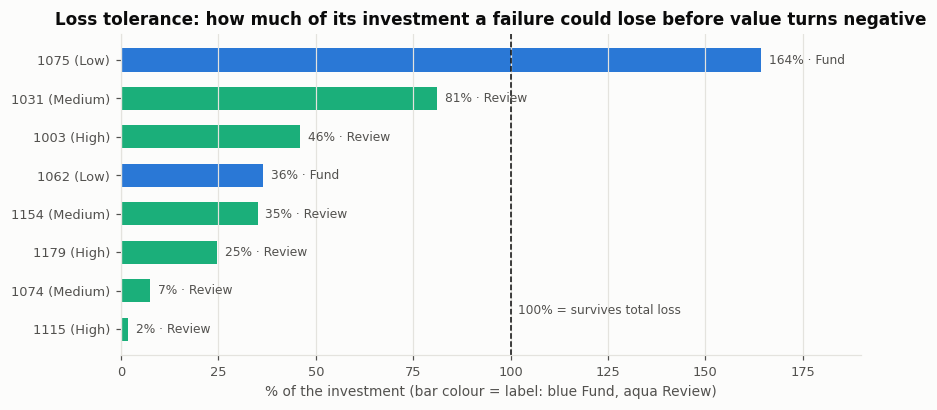

In [6]:
def loss_tolerance(table: pd.DataFrame, p_success: pd.Series) -> pd.Series:
    """L* = P × NPV ÷ ((1 − P) × Investment): the largest share of the investment a failure could
    lose before expected value turns negative. Blank (NaN) when NPV ≤ 0, where it has no meaning."""
    lt = p_success * table["NPV_3yr"] / ((1 - p_success) * table["Initial_Investment"])
    return lt.where(table["NPV_3yr"] > 0)


df["Loss_Tolerance"] = loss_tolerance(df, df["P_Success"])
df["Funding_Condition"] = np.where(df["Label"] != "Fund", "",
                                   np.where(df["Loss_Tolerance"] >= 1, "Fund in full", "Fund in stages"))

positive = (df.loc[df.NPV_3yr > 0, ["Initiative_ID", "Business_Unit", "Risk_Rating", "Label", "Initial_Investment",
                                    "NPV_3yr", "P_Success", "Expected_NPV", "Loss_Tolerance", "Funding_Condition"]]
              .sort_values("Loss_Tolerance", ascending=False))
display(positive.round({"NPV_3yr": 2, "P_Success": 3, "Expected_NPV": 2, "Loss_Tolerance": 2}))

# Chart: loss tolerance of the 8 positive-NPV initiatives; the line at 100% = survives total loss.
fig, ax = plt.subplots(figsize=(8, 3.8))
plot = positive.iloc[::-1]
ax.barh(plot["Initiative_ID"].astype(str) + " (" + plot["Risk_Rating"] + ")", plot["Loss_Tolerance"] * 100,
        color=[LABEL_COLOURS[l] for l in plot["Label"]], height=0.6)
for i, (v, lab) in enumerate(zip(plot["Loss_Tolerance"] * 100, plot["Label"])):
    ax.text(v + 2, i, f"{v:.0f}% · {lab}", va="center", color=INK_2, fontsize=8)
ax.axvline(100, color=INK, linestyle="--", linewidth=1)
ax.text(102, 0.5, "100% = survives total loss", color=INK_2, fontsize=8, va="center")   # between the two shortest bars
ax.set(title="Loss tolerance: how much of its investment a failure could lose before value turns negative",
       xlabel="% of the investment (bar colour = label: blue Fund, aqua Review)", xlim=(0, 190))
ax.grid(axis="y", visible=False)
fig.tight_layout()
save_chart(fig, "5_loss_tolerance")
plt.show()

## 6. Priority order within each label (decision M1-06, point F)

| Label | Order | Why |
| --- | --- | --- |
| Fund | Expected NPV, highest first | The brief's value measure |
| Review group 1: positive NPV, Medium/High risk | Loss tolerance, most robust first | They are in Review *because of risk*, so rank by how much a failure each can absorb |
| Review group 2: slow payers | Break-even life (fewest assumed years first), then P(Success) | Fewer assumed years means less uncertainty. P only breaks ties, so the model orders but does not decide |
| Reject | By reason, no rank | A rejected project needs a reason, not a position |

Slow payers are **not** ranked by Expected NPV: their NPV is negative, so a higher P would push the likeliest successes to the bottom.

In [7]:
def priority(table: pd.DataFrame) -> pd.Series:
    """Rank within each label / review group (1 = first). Reject gets no rank."""
    rank = pd.Series(np.nan, index=table.index)
    fund = table["Label"] == "Fund"
    g1 = table["Review_Group"].str.startswith("1")
    g2 = table["Review_Group"].str.startswith("2")
    rank[fund] = table.loc[fund, "Expected_NPV"].rank(ascending=False, method="first")
    rank[g1] = table.loc[g1, "Loss_Tolerance"].rank(ascending=False, method="first")
    # Slow payers: sort by break-even (ascending), then P (descending); position in that order = rank.
    order = table.loc[g2].sort_values(["Break_Even_Years", "P_Success"], ascending=[True, False]).index
    rank[order] = np.arange(1, len(order) + 1)
    return rank


df["Priority"] = priority(df)
print("Fund, in order:")
display(df[df.Label == "Fund"].sort_values("Priority")[["Priority", "Initiative_ID", "Business_Unit", "Risk_Rating",
        "Initial_Investment", "NPV_3yr", "Expected_NPV", "Loss_Tolerance", "Funding_Condition"]].round(2))
print("Review group 1 (positive NPV, higher risk), in order:")
display(df[df.Review_Group.str.startswith("1")].sort_values("Priority")[["Priority", "Initiative_ID", "Business_Unit",
        "Risk_Rating", "Initial_Investment", "NPV_3yr", "P_Success", "Expected_NPV", "Loss_Tolerance"]].round(2))
print("Review group 2 (slow payers), first 10 of", int(df.Review_Group.str.startswith("2").sum()))
display(df[df.Review_Group.str.startswith("2")].sort_values("Priority")[["Priority", "Initiative_ID", "Business_Unit",
        "Risk_Rating", "Initial_Investment", "NPV_3yr", "Break_Even_Years", "P_Success"]].head(10).round(2))

Fund, in order:


,Priority,Initiative_ID,Business_Unit,Risk_Rating,Initial_Investment,NPV_3yr,Expected_NPV,Loss_Tolerance,Funding_Condition
74,1.0,1075,Wealth,Low,220.85,55.57,48.19,1.64,Fund in full
61,2.0,1062,Corporate Banking,Low,103.26,9.86,7.81,0.36,Fund in stages


Review group 1 (positive NPV, higher risk), in order:


,Priority,Initiative_ID,Business_Unit,Risk_Rating,Initial_Investment,NPV_3yr,P_Success,Expected_NPV,Loss_Tolerance
30,1.0,1031,Wealth,Medium,194.04,53.69,0.75,40.05,0.81
2,2.0,1003,Wealth,High,227.64,37.74,0.73,27.72,0.46
153,3.0,1154,Wealth,Medium,162.15,31.34,0.64,20.20,0.35
178,4.0,1179,Digital Banking,High,282.92,28.61,0.71,20.31,0.25
73,5.0,1074,Corporate Banking,Medium,250.17,6.32,0.74,4.71,0.07
114,6.0,1115,SME Lending,High,201.02,1.91,0.65,1.25,0.02


Review group 2 (slow payers), first 10 of 32


,Priority,Initiative_ID,Business_Unit,Risk_Rating,Initial_Investment,NPV_3yr,Break_Even_Years,P_Success
20,1.0,1021,Digital Banking,Low,195.20,-39.28,4.0,0.89
148,2.0,1149,Payments,Low,43.90,-2.30,4.0,0.88
37,3.0,1038,Payments,Low,56.37,-3.89,4.0,0.87
161,4.0,1162,Payments,Low,200.72,-61.32,4.0,0.86
106,5.0,1107,Wealth,Low,140.80,-10.55,4.0,0.86
40,6.0,1041,Digital Banking,Low,62.95,-1.98,4.0,0.85
21,7.0,1022,Payments,Low,67.66,-12.77,4.0,0.85
25,8.0,1026,Payments,Low,242.00,-5.00,4.0,0.85
32,9.0,1033,Risk Analytics,Low,47.56,-3.48,4.0,0.84
176,10.0,1177,SME Lending,Low,216.55,-19.31,4.0,0.83


## 7. Results in ₹

What each label means in money:
- **capital:** Initial_Investment;
- **Expected NPV:** the brief's value measure.

**Past success rate** is how often initiatives like these actually succeeded (Historical_Success). It is a backtest on the same 180 initiatives, so read it as a consistency check, not as proof of future performance.

,Initiatives,Capital_crore,Expected_NPV_lakh,Mean_P,Past_success,Failed_capital_crore,Share_of_capital
Label,,,,,,,
Fund,2,3.241,56.006,0.830,0.500,2.208,0.011
Review,38,62.946,-1006.572,0.812,0.842,9.157,0.222
Reject,140,217.260,-8931.084,0.729,0.750,54.151,0.766


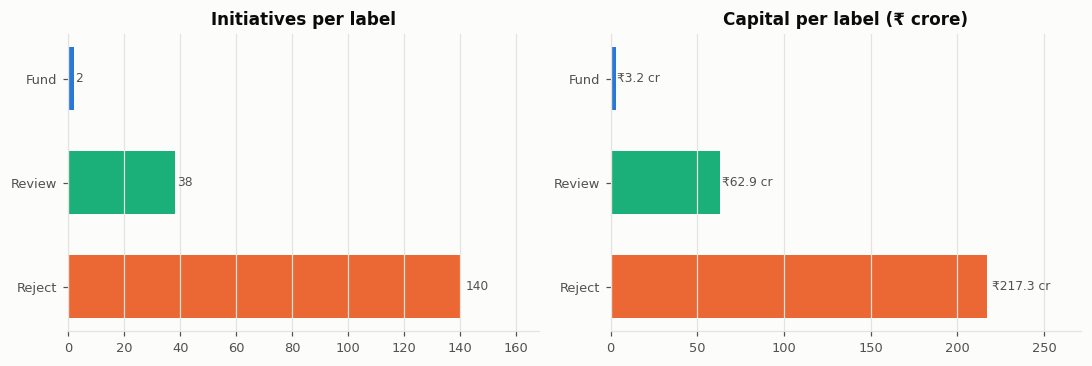

In [8]:
by_label = (df.assign(Failed_Capital=df.Initial_Investment.where(df.Historical_Success == 0, 0))
              .groupby("Label")
              .agg(Initiatives=("Initiative_ID", "size"),
                   Capital_crore=("Initial_Investment", lambda x: x.sum() / 100),
                   Expected_NPV_lakh=("Expected_NPV", "sum"),
                   Mean_P=("P_Success", "mean"),
                   Past_success=("Historical_Success", "mean"),
                   Failed_capital_crore=("Failed_Capital", lambda x: x.sum() / 100))
              .reindex(["Fund", "Review", "Reject"]))
by_label["Share_of_capital"] = by_label["Capital_crore"] / (df.Initial_Investment.sum() / 100)
display(by_label.round(3))

fig, axes = plt.subplots(1, 2, figsize=(10, 3.4))
names = list(by_label.index)[::-1]
colours = [LABEL_COLOURS[n] for n in names]
axes[0].barh(names, by_label["Initiatives"][::-1], color=colours, height=0.6)
axes[1].barh(names, by_label["Capital_crore"][::-1], color=colours, height=0.6)
for ax, col, fmt in [(axes[0], "Initiatives", "{:.0f}"), (axes[1], "Capital_crore", "₹{:.1f} cr")]:
    for i, v in enumerate(by_label[col][::-1]):
        ax.text(v * 1.01 + 0.5, i, fmt.format(v), va="center", color=INK_2, fontsize=8)
    ax.grid(axis="y", visible=False)
axes[0].set(title="Initiatives per label", xlim=(0, by_label["Initiatives"].max() * 1.2))
axes[1].set(title="Capital per label (₹ crore)", xlim=(0, by_label["Capital_crore"].max() * 1.25))
fig.tight_layout()
save_chart(fig, "7_decision_summary")
plt.show()

## 7b. Decisions by business unit and risk level

How the labels split across the six business units and the three risk levels, in number of initiatives and in ₹ crore of capital. These are Task 3's own results. What they mean against Task 1's findings (for example, Corporate Banking) is discussed in the module report.

In [9]:
def label_split(group_col: str) -> pd.DataFrame:
    """Number of initiatives and capital (₹ crore) per label, for each value of group_col."""
    labels = ["Fund", "Review", "Reject"]
    counts = pd.crosstab(df[group_col], df["Label"]).reindex(columns=labels, fill_value=0)
    capital = (df.pivot_table(index=group_col, columns="Label", values="Initial_Investment",
                              aggfunc="sum", fill_value=0) / 100).reindex(columns=labels, fill_value=0)
    out = pd.concat([counts, capital.add_suffix(" (₹ crore)").round(1)], axis=1)
    out["Total"] = counts.sum(axis=1)
    out["Reject share"] = (counts["Reject"] / out["Total"]).round(3)    # e.g. 27 of 35 = 0.771
    return out


by_unit = label_split("Business_Unit")
by_risk = label_split("Risk_Rating").reindex(["Low", "Medium", "High"])
save_table(by_unit.reset_index(), "7b_by_unit")
save_table(by_risk.reset_index(), "7b_by_risk")
print("By business unit:")
display(by_unit)
print("By risk level:")
display(by_risk)

By business unit:


Label,Fund,Review,Reject,Fund (₹ crore),Review (₹ crore),Reject (₹ crore),Total,Reject share
Business_Unit,,,,,,,,
Corporate Banking,1,7,27,1.0,14.8,46.5,35,0.771
Digital Banking,0,7,27,0.0,9.3,37.8,34,0.794
Payments,0,7,29,0.0,10.1,43.2,36,0.806
Risk Analytics,0,7,18,0.0,11.5,28.3,25,0.720
SME Lending,0,2,13,0.0,4.2,18.1,15,0.867
Wealth,1,8,26,2.2,13.1,43.3,35,0.743


By risk level:


Label,Fund,Review,Reject,Fund (₹ crore),Review (₹ crore),Reject (₹ crore),Total,Reject share
Risk_Rating,,,,,,,,
Low,2,25,37,3.2,40.3,55.1,64,0.578
Medium,0,9,63,0.0,15.2,104.3,72,0.875
High,0,4,40,0.0,7.5,57.9,44,0.909


## 8. Sensitivity 1: where P(Success) comes from, i.e. what the ML adds (decisions M1-20, M1-23)

Task 2 found that lasso's probabilities are only as accurate as saying 77% for everyone, and that its ranking power comes from the risk rating. So the Board should see how much the decisions depend on the model. We rerun the **same rule** three times, changing only where P(Success) comes from:

| Run | P(Success) | What it represents |
| --- | --- | --- |
| **Main: lasso** | Task 2's out-of-fold probability per initiative | The brief's chain: the ML prediction feeds the decision |
| No model | 0.767 for every initiative (the base rate) | What we would decide with no prediction at all |
| Risk rating only | The success rate of the initiative's risk level: Low 0.89, Medium 0.69, High 0.70 | What the bank's own rating alone would decide (Task 2's benchmark) |

**Where P can matter in the rule:**
- P > 0 always, so it never changes the sign of Expected NPV. **Fund cannot change.**
- P matters in the **slow-payer gate** (point C), in the loss tolerance, and in the order of the lists.
- With a flat 0.767, every slow payer passes the gate (P is exactly the line), so the gate stops filtering.

The risk-level rates are computed on all 180 initiatives. That is fine for a "what if" run, which is not a score.

,Fund,Review,Reject,Review capital (₹ crore),Review past success,Decisions different from main
Main: lasso,2.0,38.0,140.0,62.946,0.842,0.0
No model (0.767 for all),2.0,74.0,104.0,117.292,0.757,36.0
Risk rating only,2.0,31.0,147.0,53.477,0.839,7.0


,Alternative run,Main label,Label in this run,Risk_Rating,Initiatives
0,No model (0.767 for all),Reject,Review,High,11
1,No model (0.767 for all),Reject,Review,Medium,25
2,Risk rating only,Review,Reject,High,1
3,Risk rating only,Review,Reject,Medium,6


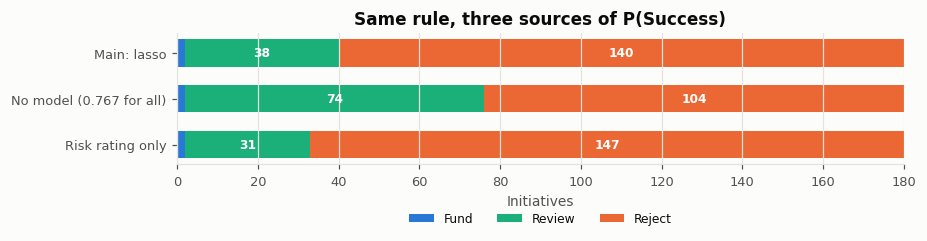

In [10]:
RUNS = {
    "Main: lasso": df["P_Success"],
    "No model (0.767 for all)": pd.Series(BASE_RATE, index=df.index),
    "Risk rating only": df["Risk_Rating"].map(df.groupby("Risk_Rating")["Historical_Success"].mean()),
}
labels = pd.DataFrame({name: decide(df, p)["Label"] for name, p in RUNS.items()})

runs_table = pd.DataFrame({
    name: {
        "Fund": int((labels[name] == "Fund").sum()),
        "Review": int((labels[name] == "Review").sum()),
        "Reject": int((labels[name] == "Reject").sum()),
        "Review capital (₹ crore)": df.loc[labels[name] == "Review", "Initial_Investment"].sum() / 100,
        "Review past success": df.loc[labels[name] == "Review", "Historical_Success"].mean(),
        "Decisions different from main": int((labels[name] != labels["Main: lasso"]).sum()),
    } for name in RUNS}).T
display(runs_table.round(3))

# Which initiatives change, and how (main run vs each alternative).
changes = []
for name in list(RUNS)[1:]:
    moved = labels[name] != labels["Main: lasso"]
    for i in df.index[moved]:
        changes.append({"Alternative run": name, "Initiative_ID": df.at[i, "Initiative_ID"],
                        "Risk_Rating": df.at[i, "Risk_Rating"], "Business_Unit": df.at[i, "Business_Unit"],
                        "Lasso P": round(df.at[i, "P_Success"], 3), "Main label": labels.at[i, "Main: lasso"],
                        "Label in this run": labels.at[i, name]})
changes = pd.DataFrame(changes)
display(changes.groupby(["Alternative run", "Main label", "Label in this run", "Risk_Rating"]).size()
               .rename("Initiatives").reset_index())

fig, ax = plt.subplots(figsize=(8.5, 2.8))
left = np.zeros(len(RUNS))
for lab in ["Fund", "Review", "Reject"]:
    vals = np.array([(labels[n] == lab).sum() for n in RUNS])
    ax.barh(list(RUNS), vals, left=left, color=LABEL_COLOURS[lab], height=0.6, label=lab)
    for i, (l, v) in enumerate(zip(left, vals)):
        if v >= 6:
            ax.text(l + v / 2, i, str(v), va="center", ha="center", color="white", fontsize=8, fontweight="bold")
    left += vals
ax.invert_yaxis()
ax.set(title="Same rule, three sources of P(Success)", xlabel="Initiatives", xlim=(0, len(df)))
ax.legend(ncol=3, fontsize=8, frameon=False, loc="lower center", bbox_to_anchor=(0.5, -0.55))
ax.grid(axis="y", visible=False)
fig.tight_layout()
save_chart(fig, "8_sensitivity_p_source")
plt.show()

## 9. Sensitivity 2: the break-even cut-off (decision M1-06, point D)

The 5-year cut-off is a finance tolerance choice: how many years of cash *beyond the data* the Board will rely on (cut-off − 3). The same rule (main P) is rerun at 4 and 6 years.

In [11]:
cutoffs = pd.DataFrame({
    f"{years} years": {
        "Years assumed beyond the data": years - 3,
        "Fund": int((decide(df, df.P_Success, review_years=years)["Label"] == "Fund").sum()),
        "Review": int((decide(df, df.P_Success, review_years=years)["Label"] == "Review").sum()),
        "of which slow payers": int((decide(df, df.P_Success, review_years=years)["Review_Group"].str.startswith("2")).sum()),
        "Reject": int((decide(df, df.P_Success, review_years=years)["Label"] == "Reject").sum()),
        "Review capital (₹ crore)": df.loc[decide(df, df.P_Success, review_years=years)["Label"] == "Review",
                                           "Initial_Investment"].sum() / 100,
    } for years in [4, 5, 6]}).T
display(cutoffs.round(1))

,Years assumed beyond the data,Fund,Review,of which slow payers,Reject,Review capital (₹ crore)
4 years,1.0,2.0,21.0,15.0,157.0,33.0
5 years,2.0,2.0,38.0,32.0,140.0,62.9
6 years,3.0,2.0,47.0,41.0,131.0,77.6


## 10. Board view and hand-off to Module 9

**For the Board:**
- **Fund:** the list, with its funding condition (in full or in stages).
- **Review:** two ordered lists, with what to look at in each.
- **Reject:** the reasons, counted.

**For Module 9** (the ₹1,000 crore allocation): the Fund capital, the Review capital (an upper bound if every Review project were approved), and Expected NPV. The full table `outputs/task3/FINAL_M1_T3_initiative_decisions.csv` is the hand-off.

In [12]:
fund_capital = df.loc[df.Label == "Fund", "Initial_Investment"].sum() / 100
review_capital = df.loc[df.Label == "Review", "Initial_Investment"].sum() / 100
print(f"Fund:   {int((df.Label == 'Fund').sum())} initiatives, ₹{fund_capital:.1f} crore "
      f"(Expected NPV ₹{df.loc[df.Label == 'Fund', 'Expected_NPV'].sum():.1f} lakh)")
print(f"Review: {int((df.Label == 'Review').sum())} initiatives, up to ₹{review_capital:.1f} crore if all were approved")
print(f"Reject: {int((df.Label == 'Reject').sum())} initiatives, ₹{df.loc[df.Label == 'Reject', 'Initial_Investment'].sum() / 100:.1f} crore not requested further")
print(f"Share of the Board's ₹1,000 crore: Fund {fund_capital / 1000:.1%}; Fund + all Review {(fund_capital + review_capital) / 1000:.1%}")

reasons = (df[df.Label == "Reject"].groupby("Reason_Code").agg(Initiatives=("Initiative_ID", "size"),
           Capital_crore=("Initial_Investment", lambda x: x.sum() / 100))
           .rename(index=DECISION_PATH))
print("Why initiatives were rejected:")
display(reasons.round(1))

Fund:   2 initiatives, ₹3.2 crore (Expected NPV ₹56.0 lakh)
Review: 38 initiatives, up to ₹62.9 crore if all were approved
Reject: 140 initiatives, ₹217.3 crore not requested further
Share of the Board's ₹1,000 crore: Fund 0.3%; Fund + all Review 6.6%
Why initiatives were rejected:


,Initiatives,Capital_crore
Reason_Code,,
Reject: never pays back,17,24.1
Reject: pays back after the 5-year limit,79,132.1
Reject: fails the hurdle,8,6.7
Reject: flagged at risk by the model,36,54.3


## 10b. The Board decision file: every check, in words

The decision for each initiative rests on **several checks**, not one: value (NPV and Expected NPV), risk rating, payback (break-even life), the hurdle, the model's "at risk" flag and loss tolerance. The decision file shows **all of them for every initiative**, as readable text, so a Board member can see why each initiative landed where it did, including the checks that passed.

- **No blank cells.** Where a check doesn't apply, the cell says so and why. For example, loss tolerance is "Not applicable: NPV not positive", because it is only defined for initiatives that create value.
- **No codes.** The decision path is written out in words.
- **Full reason:** one sentence naming the **deciding factor first**, then the other checks.
- The money columns (investment, NPV, P(Success), Expected NPV) stay as numbers, complete for every row, so Module 9 can add them up.

In [13]:
def check_texts(row) -> dict:
    """Every agreed check for one initiative, as short readable text (no blanks)."""
    npv, e, p = row.NPV_3yr, row.Expected_NPV, row.P_Success
    be, lt = row.Break_Even_Years, row.Loss_Tolerance
    checks = {}
    checks["Check: value"] = (f"Positive: NPV +{npv:.1f}, Expected NPV +{e:.1f}" if npv > 0
                              else f"Not positive: NPV {npv:.1f}, Expected NPV {e:.1f}")
    checks["Check: risk"] = ("Low: acceptable for Fund" if row.Risk_Rating == "Low"
                             else f"{row.Risk_Rating}: not acceptable for Fund without review")
    if pd.isna(be):
        checks["Check: payback"] = "Never pays back (within 30 years)"
    elif be <= REVIEW_YEARS:
        checks["Check: payback"] = f"Year {int(be)}: within the {REVIEW_YEARS}-year limit"
    else:
        checks["Check: payback"] = f"Year {int(be)}: after the {REVIEW_YEARS}-year limit"
    checks["Check: hurdle"] = (f"Pass: Expected_ROI {row.Expected_ROI:.1f}% > cost of money {row.Interest_Rate:.1f}%"
                               if row.Passes_Hurdle else
                               f"Fail: Expected_ROI {row.Expected_ROI:.1f}% ≤ cost of money {row.Interest_Rate:.1f}%")
    checks["Check: model"] = (f"Not at risk: P(Success) {p:.2f} ≥ {BASE_RATE:.3f}" if p >= BASE_RATE
                              else f"At risk: P(Success) {p:.2f} < {BASE_RATE:.3f}")
    if pd.isna(lt):
        checks["Check: loss tolerance"] = "Not applicable: NPV not positive"
    elif lt >= 1:
        checks["Check: loss tolerance"] = f"{lt:.0%}: survives even a total loss"
    else:
        checks["Check: loss tolerance"] = f"{lt:.0%}: worth it only if a failure loses at most {lt:.0%} of the investment"
    return checks


def priority_text(row) -> str:
    """Position in its list, in words."""
    if row.Label == "Fund":
        return f"Fund #{int(row.Priority)} of {int((df.Label == 'Fund').sum())}"
    if row.Review_Group.startswith("1"):
        return f"Review group 1 (positive value, higher risk): #{int(row.Priority)} of {int(df.Review_Group.str.startswith('1').sum())}"
    if row.Review_Group.startswith("2"):
        return f"Review group 2 (slow payers): #{int(row.Priority)} of {int(df.Review_Group.str.startswith('2').sum())}"
    return "Not ranked: rejected"


def full_reason(row, c: dict) -> str:
    """One sentence: the deciding factor first, then the other checks."""
    code = row.Reason_Code
    other = lambda *keys: "; ".join(c[k] for k in keys)
    if code == "F1":
        how = "survives even a total loss" if row.Loss_Tolerance >= 1 else "so money is released in stages"
        return (f"{row.Funding_Condition}: positive value (NPV +{row.NPV_3yr:.1f}, Expected NPV +{row.Expected_NPV:.1f}) "
                f"and Low risk; loss tolerance {row.Loss_Tolerance:.0%}, {how}. Other checks: "
                + other("Check: payback", "Check: hurdle", "Check: model") + ".")
    if code == "R1":
        return (f"Review: positive value (NPV +{row.NPV_3yr:.1f}, Expected NPV +{row.Expected_NPV:.1f}) but "
                f"{row.Risk_Rating} risk; loss tolerance {row.Loss_Tolerance:.0%} (how much a failure could lose before it "
                f"stops being worth it). Other checks: " + other("Check: payback", "Check: hurdle", "Check: model") + ".")
    if code == "R2":
        return (f"Review (slow payer): NPV {row.NPV_3yr:.1f} over 3 years (Expected NPV {row.Expected_NPV:.1f}), but "
                f"pays back in year {int(row.Break_Even_Years)}, passes the hurdle and is not flagged by the model. "
                f"Details: " + other("Check: hurdle", "Check: model", "Check: risk") + ".")
    if code == "X1":
        return (f"Reject: never pays back. Other checks: " + other("Check: value", "Check: hurdle", "Check: model", "Check: risk") + ".")
    if code == "X2":
        return (f"Reject: pays back only in year {int(row.Break_Even_Years)} (limit {REVIEW_YEARS}). Other checks: "
                + other("Check: value", "Check: hurdle", "Check: model", "Check: risk") + ".")
    if code == "X3":
        return (f"Reject: fails the hurdle (promises less than its cost of money). Other checks: "
                + other("Check: value", "Check: payback", "Check: model", "Check: risk") + ".")
    return (f"Reject: flagged at risk by the model (P(Success) {row.P_Success:.2f} < {BASE_RATE:.3f}), although the "
            f"finance checks pass: " + other("Check: payback", "Check: hurdle", "Check: value", "Check: risk") + ".")


rows = []
for _, row in df.iterrows():
    c = check_texts(row)
    rows.append({
        "Initiative_ID": row.Initiative_ID, "Business_Unit": row.Business_Unit, "Risk_Rating": row.Risk_Rating,
        "Investment (₹ lakh)": round(row.Initial_Investment, 2), "NPV 3 years (₹ lakh)": round(row.NPV_3yr, 2),
        "P(Success)": round(row.P_Success, 4), "Expected NPV (₹ lakh)": round(row.Expected_NPV, 2),
        **c,
        "Decision": row.Label,
        "Decision path": row.Decision_Path,
        "Funding condition": (row.Funding_Condition if row.Label == "Fund"
                              else "Not applicable: decided after review" if row.Label == "Review"
                              else "Not applicable: rejected"),
        "Priority": priority_text(row),
        "Full reason": full_reason(row, c),
        "_l": {"Fund": 0, "Review": 1, "Reject": 2}[row.Label],         # sort keys (dropped before saving)
        "_g": row.Review_Group,
        "_p": row.Priority if pd.notna(row.Priority) else 999,
    })
board_decision_file = (pd.DataFrame(rows).sort_values(["_l", "_g", "_p", "Decision path"])
                         .drop(columns=["_l", "_g", "_p"]).reset_index(drop=True))
assert board_decision_file.notna().all().all(), "the Board file must have no blank cells"
with pd.option_context("display.max_colwidth", None):
    display(board_decision_file.head(4))
print("Example reasons:")
for i in [0, 2, len(board_decision_file) - 1]:
    print("-", board_decision_file.at[i, "Initiative_ID"], board_decision_file.at[i, "Full reason"])

,Initiative_ID,Business_Unit,Risk_Rating,Investment (₹ lakh),NPV 3 years (₹ lakh),P(Success),Expected NPV (₹ lakh),Check: value,Check: risk,Check: payback,Check: hurdle,Check: model,Check: loss tolerance,Decision,Decision path,Funding condition,Priority,Full reason
0,1075,Wealth,Low,220.85,55.57,0.8672,48.19,"Positive: NPV +55.6, Expected NPV +48.2",Low: acceptable for Fund,Year 3: within the 5-year limit,Pass: Expected_ROI 18.9% > cost of money 5.9%,Not at risk: P(Success) 0.87 ≥ 0.767,164%: survives even a total loss,Fund,"Fund: positive value, Low risk",Fund in full,Fund #1 of 2,"Fund in full: positive value (NPV +55.6, Expected NPV +48.2) and Low risk; loss tolerance 164%, survives even a total loss. Other checks: Year 3: within the 5-year limit; Pass: Expected_ROI 18.9% > cost of money 5.9%; Not at risk: P(Success) 0.87 ≥ 0.767."
1,1062,Corporate Banking,Low,103.26,9.86,0.7922,7.81,"Positive: NPV +9.9, Expected NPV +7.8",Low: acceptable for Fund,Year 3: within the 5-year limit,Pass: Expected_ROI 15.4% > cost of money 7.2%,Not at risk: P(Success) 0.79 ≥ 0.767,36%: worth it only if a failure loses at most 36% of the investment,Fund,"Fund: positive value, Low risk",Fund in stages,Fund #2 of 2,"Fund in stages: positive value (NPV +9.9, Expected NPV +7.8) and Low risk; loss tolerance 36%, so money is released in stages. Other checks: Year 3: within the 5-year limit; Pass: Expected_ROI 15.4% > cost of money 7.2%; Not at risk: P(Success) 0.79 ≥ 0.767."
2,1031,Wealth,Medium,194.04,53.69,0.7459,40.05,"Positive: NPV +53.7, Expected NPV +40.0",Medium: not acceptable for Fund without review,Year 3: within the 5-year limit,Pass: Expected_ROI 14.8% > cost of money 5.3%,At risk: P(Success) 0.75 < 0.767,81%: worth it only if a failure loses at most 81% of the investment,Review,Review: positive value but Medium/High risk,Not applicable: decided after review,"Review group 1 (positive value, higher risk): #1 of 6","Review: positive value (NPV +53.7, Expected NPV +40.0) but Medium risk; loss tolerance 81% (how much a failure could lose before it stops being worth it). Other checks: Year 3: within the 5-year limit; Pass: Expected_ROI 14.8% > cost of money 5.3%; At risk: P(Success) 0.75 < 0.767."
3,1003,Wealth,High,227.64,37.74,0.7346,27.72,"Positive: NPV +37.7, Expected NPV +27.7",High: not acceptable for Fund without review,Year 3: within the 5-year limit,Pass: Expected_ROI 15.7% > cost of money 7.4%,At risk: P(Success) 0.73 < 0.767,46%: worth it only if a failure loses at most 46% of the investment,Review,Review: positive value but Medium/High risk,Not applicable: decided after review,"Review group 1 (positive value, higher risk): #2 of 6","Review: positive value (NPV +37.7, Expected NPV +27.7) but High risk; loss tolerance 46% (how much a failure could lose before it stops being worth it). Other checks: Year 3: within the 5-year limit; Pass: Expected_ROI 15.7% > cost of money 7.4%; At risk: P(Success) 0.73 < 0.767."


Example reasons:
- 1075 Fund in full: positive value (NPV +55.6, Expected NPV +48.2) and Low risk; loss tolerance 164%, survives even a total loss. Other checks: Year 3: within the 5-year limit; Pass: Expected_ROI 18.9% > cost of money 5.9%; Not at risk: P(Success) 0.87 ≥ 0.767.
- 1031 Review: positive value (NPV +53.7, Expected NPV +40.0) but Medium risk; loss tolerance 81% (how much a failure could lose before it stops being worth it). Other checks: Year 3: within the 5-year limit; Pass: Expected_ROI 14.8% > cost of money 5.3%; At risk: P(Success) 0.75 < 0.767.
- 1180 Reject: pays back only in year 6 (limit 5). Other checks: Not positive: NPV -32.2, Expected NPV -26.5; Pass: Expected_ROI 8.2% > cost of money 7.7%; Not at risk: P(Success) 0.82 ≥ 0.767; Low: acceptable for Fund.


## 10c. What goes to Module 9: return and risk per ₹, by business unit (decision M1-24)
Module 9 compares every business on the **same fields**: return per ₹ deployed (a year), a bad-case result, capacity, evidence, how fast money comes back, gaps and controls. Module 1's data has investment, revenue and costs **by business unit**, so it gives Digital banking, Payments and Wealth a return per ₹ of capital that no other file has.

**How it is worked out** (Module 1's own rules):
- Cash flow in years 1–3 from the data; **years 4–5 repeat year 3** (the 5-year payback limit, M1-04).
- **Return per ₹ a year = the internal rate of return (IRR)**: the yearly rate at which the money put in and the cash coming back balance out (0 = just get the money back).
- **Expected return:** each initiative's cash × its P(Success) from Task 2; **a failed initiative returns no cash** (its investment is lost; stricter than Expected NPV = P × NPV, which treats failure as break-even).
- **Bad case (1 in 20):** 2,000 random draws of which initiatives succeed (each with its own P(Success), seed 42); the 5th-worst percentile.
- Shown for the **deployable set (Fund + Review)** and, for comparison, for all initiatives.

In [14]:
from scipy.optimize import brentq


def irr(flows) -> float:
    """Yearly rate at which today's investment (negative) and later cash (positive) balance out."""
    f = lambda r: sum(c / (1 + r) ** t for t, c in enumerate(flows))
    try:
        return brentq(f, -0.99, 1.0)
    except ValueError:                       # no rate in range: cash never balances the investment
        return np.nan


cf3 = np.c_[[df[f"Revenue_Year{t}"] - df.Operating_Cost for t in (1, 2, 3)]].T           # ₹ lakh, years 1–3
CF5 = np.c_[cf3, cf3[:, 2], cf3[:, 2]]                                                  # years 4–5 = year 3
INV, PS = df.Initial_Investment.to_numpy(), df.P_Success.to_numpy()
SEED = 42                                                                  # project rule P-06 (this step is the only random one in Task 3)
bu_rng = np.random.default_rng(SEED)
bu_rows = []
for scope, mask in [("Fund + Review (deployable)", (df.Label != "Reject").to_numpy()), ("All initiatives", np.ones(len(df), bool))]:
    for unit in sorted(df.Business_Unit.unique()) + ["All units"]:
        m = mask & ((df.Business_Unit == unit).to_numpy() if unit != "All units" else True)
        if not m.any():
            continue
        I = INV[m].sum()
        draws = [irr([-I, *((bu_rng.random(m.sum()) < PS[m])[:, None] * CF5[m]).sum(0)]) for _ in range(2000)]
        bu_rows.append({"Scope": scope, "Business unit": unit, "Initiatives": int(m.sum()),
                        "Fund now (₹ crore)": INV[m & (df.Label == "Fund").to_numpy()].sum() / 100, "Capacity (₹ crore)": I / 100,
                        "Return if every initiative succeeds (% a year)": irr([-I, *CF5[m].sum(0)]) * 100,
                        "Expected return (% a year)": irr([-I, *(PS[m, None] * CF5[m]).sum(0)]) * 100,
                        "1-in-20 bad case (% a year)": np.nanpercentile(draws, 5) * 100, "Average P(Success)": PS[m].mean()})
bu_table = pd.DataFrame(bu_rows)
display(bu_table.round(2))
dep = bu_table[bu_table.Scope.str.startswith("Fund")].set_index("Business unit")
print(f"Deployable initiatives: ₹{dep.loc['All units', 'Capacity (₹ crore)']:.1f} crore, expected {dep.loc['All units', 'Expected return (% a year)']:.1f}% a year "
      f"(1-in-20 bad case {dep.loc['All units', '1-in-20 bad case (% a year)']:.1f}%). Rejected initiatives would earn less in every unit: "
      "Module 1's rejections are confirmed on a return-per-₹ basis.")

# The standard Module 9 fields, one row per business unit (same columns in every module)
CATEGORY = {"Corporate Banking": "Corporate lending (initiatives)", "Digital Banking": "Digital banking (initiatives)",
            "Payments": "Digital banking (payments initiatives)", "Wealth": "Wealth management (initiatives)",
            "SME Lending": "Retail lending (SME initiatives)", "Risk Analytics": "Risk management (analytics initiatives)"}
m9_rows = []
for unit, r in dep.drop(index="All units").iterrows():
    m9_rows.append({"Category": CATEGORY[unit], "What NovaFin would put money into":
                        f"The {int(r.Initiatives)} Fund + Review initiatives of the {unit} unit (₹{r['Fund now (₹ crore)']:.2f} crore fundable now)",
                    "Return per ₹ deployed (% a year)": round(r["Expected return (% a year)"], 1),
                    "Return range (% a year)": f"{r['1-in-20 bad case (% a year)']:.1f} (1-in-20 bad case) to {r['Return if every initiative succeeds (% a year)']:.1f} (all succeed)",
                    "Bad-year result per ₹ (% a year)": round(r["1-in-20 bad case (% a year)"], 1),
                    "How the bad year is defined": "1-in-20 outcome of which initiatives succeed (each with its P(Success); a failure returns no cash), as a yearly return over 5 years",
                    "Capacity (₹ crore)": round(r["Capacity (₹ crore)"], 2), "Evidence strength": "Weak: P(Success) model ROC-AUC 0.58; years 4–5 assumed equal to year 3",
                    "How fast the money can come back": "Locked in for about 5 years (payback limit)",
                    "Data gap or assumption": "Cash after year 3 is assumed; Review money flows only if a review approves it",
                    "Controls": "Fund in stages, release at milestones; Review approval in priority order before money flows",
                    "Detail tab": "T3 initiative decisions", "Detail column(s)": "Business_Unit, Decision, Investment (₹ lakh), P(Success)",
                    "Decision": "M1-24"})
m9_inputs = pd.DataFrame(m9_rows)
display(m9_inputs[["Category", "Return per ₹ deployed (% a year)", "Bad-year result per ₹ (% a year)", "Capacity (₹ crore)"]])

,Scope,Business unit,Initiatives,Fund now (₹ crore),Capacity (₹ crore),Return if every initiative succeeds (% a year),Expected return (% a year),1-in-20 bad case (% a year),Average P(Success)
0,Fund + Review (deployable),Corporate Banking,8,1.03,15.81,14.32,6.33,-6.13,0.80
1,Fund + Review (deployable),Digital Banking,7,0.00,9.34,22.31,13.20,-6.64,0.81
2,Fund + Review (deployable),Payments,7,0.00,10.08,18.78,13.00,-2.14,0.86
3,Fund + Review (deployable),Risk Analytics,7,0.00,11.50,18.52,10.45,-5.35,0.81
4,Fund + Review (deployable),SME Lending,2,0.00,4.18,25.90,13.34,-1.42,0.74
5,Fund + Review (deployable),Wealth,9,2.21,15.28,27.74,17.59,3.57,0.80
6,Fund + Review (deployable),All units,40,3.24,66.19,20.75,12.13,5.95,0.81
7,All initiatives,Corporate Banking,35,1.03,62.32,5.51,-4.36,-10.10,0.71
8,All initiatives,Digital Banking,34,0.00,47.14,6.11,-1.90,-8.49,0.77
9,All initiatives,Payments,36,0.00,53.33,3.72,-4.39,-10.31,0.75


Deployable initiatives: ₹66.2 crore, expected 12.1% a year (1-in-20 bad case 5.9%). Rejected initiatives would earn less in every unit: Module 1's rejections are confirmed on a return-per-₹ basis.


,Category,Return per ₹ deployed (% a year),Bad-year result per ₹ (% a year),Capacity (₹ crore)
0,Corporate lending (initiatives),6.3,-6.1,15.81
1,Digital banking (initiatives),13.2,-6.6,9.34
2,Digital banking (payments initiatives),13.0,-2.1,10.08
3,Risk management (analytics initiatives),10.4,-5.4,11.50
4,Retail lending (SME initiatives),13.3,-1.4,4.18
5,Wealth management (initiatives),17.6,3.6,15.28


## 11. Save the outputs

- `FINAL_M1_T3_initiative_decisions.csv`: the **Board decision file** from step 10b. One row per initiative: the money columns, every check in words, decision, decision path, funding condition, priority and full reason. No blank cells and no codes. This is the hand-off to Module 9.
- `module9_inputs.csv` and `10c_business_unit_returns.csv`: the standard Module 9 fields by business unit (step 10c).
- Summary tables and the charts above, plus `key_numbers.json` for checking that the standalone and runner results match (P-16).

In [15]:
save_table(board_decision_file, "FINAL_M1_T3_initiative_decisions")      # the Board decision file (step 10b)
save_table(counts, "4_reason_counts")
save_table(positive.round(4), "5_loss_tolerance")
save_table(by_label.round(4).reset_index(), "7_results_by_label")
save_table(runs_table.round(4).reset_index(names="Run"), "8_sensitivity_p_source")
save_table(changes, "8_sensitivity_changes")
save_table(cutoffs.round(4).reset_index(names="Cut-off"), "9_sensitivity_cutoff")
save_table(bu_table.round(4), "10c_business_unit_returns")
save_table(m9_inputs, "module9_inputs")                                   # the standard Module 9 fields (step 10c)

key = {
    "fund": int((df.Label == "Fund").sum()), "review": int((df.Label == "Review").sum()),
    "reject": int((df.Label == "Reject").sum()),
    "fund_ids": df.loc[df.Label == "Fund"].sort_values("Priority")["Initiative_ID"].tolist(),
    "fund_conditions": df.loc[df.Label == "Fund"].sort_values("Priority")["Funding_Condition"].tolist(),
    "fund_capital_crore": round(float(fund_capital), 2), "review_capital_crore": round(float(review_capital), 2),
    "reject_reasons": counts[counts.Label == "Reject"].set_index("Decision_Path")["Initiatives"].to_dict(),
    "sensitivity_p_source": {n: {"fund": int(r.Fund), "review": int(r.Review), "reject": int(r.Reject),
                                 "changed": int(r["Decisions different from main"])} for n, r in runs_table.iterrows()},
    "sensitivity_cutoff_review": {k: int(v) for k, v in cutoffs["Review"].items()},
    "module9_by_unit": {u: {"capacity_crore": round(float(r["Capacity (₹ crore)"]), 2), "expected_return_pct": round(float(r["Expected return (% a year)"]), 2),
                            "bad_case_pct": round(float(r["1-in-20 bad case (% a year)"]), 2)} for u, r in dep.iterrows()},
}
(OUT_DIR / "key_numbers.json").write_text(json.dumps(key, indent=2, default=int), encoding="utf-8")
print(json.dumps(key, indent=2, default=int))

{
  "fund": 2,
  "review": 38,
  "reject": 140,
  "fund_ids": [
    1075,
    1062
  ],
  "fund_conditions": [
    "Fund in full",
    "Fund in stages"
  ],
  "fund_capital_crore": 3.24,
  "review_capital_crore": 62.95,
  "reject_reasons": {
    "Reject: pays back after the 5-year limit": 79,
    "Reject: flagged at risk by the model": 36,
    "Reject: never pays back": 17,
    "Reject: fails the hurdle": 8
  },
  "sensitivity_p_source": {
    "Main: lasso": {
      "fund": 2,
      "review": 38,
      "reject": 140,
      "changed": 0
    },
    "No model (0.767 for all)": {
      "fund": 2,
      "review": 74,
      "reject": 104,
      "changed": 36
    },
    "Risk rating only": {
      "fund": 2,
      "review": 31,
      "reject": 147,
      "changed": 7
    }
  },
  "sensitivity_cutoff_review": {
    "4 years": 21,
    "5 years": 38,
    "6 years": 47
  },
  "module9_by_unit": {
    "Corporate Banking": {
      "capacity_crore": 15.81,
      "expected_return_pct": 6.33,
      "b

## 12. What the results say: the finance case, the ML case, and the decision

*(Numbers from the run saved in `outputs/task3/`. Full write-up with charts: `reports/task3_report.md`.)*

### 12.1 The finance case
1. **On 3 years of cash, almost nothing repays itself.** Only 8 of 180 initiatives have a positive NPV (M1-03), so only they can have a positive Expected NPV.
2. **Fund: 2 initiatives, ₹3.2 crore.**
   - Only Low risk counts as acceptable (point B).
   - **1075** (Wealth) has Expected NPV +48.2 lakh and survives even total loss (loss tolerance 164%), so it is **funded in full**.
   - **1062** (Corporate Banking) has Expected NPV +7.8 lakh but stays worth it only if a failure loses no more than about 36%, so it is **funded in stages**.
3. **Review: 38 initiatives, ₹62.9 crore**, in two ordered lists.
   - **Group 1, 6 positive-NPV projects with Medium/High risk.** These are value-creating but riskier. Ordered by loss tolerance: 1031 can absorb an 81% loss; 1074 and 1115 only 7% and 2%, so they need near-certain success to be worth it.
   - **Group 2, 32 slow payers.** These break even in year 4 or 5, beat their cost of money, and are not flagged at risk. 25 are Low risk.
   - Historically, initiatives like those in Review succeeded 84% of the time, against 75% for those rejected. That is a backtest on the same initiatives, a consistency check rather than proof.
4. **Reject: 140 initiatives.** The reasons:
   - 79 break even only after 5 years;
   - 17 never break even;
   - 8 promise less than their cost of money;
   - 36 pass every finance check but are flagged at risk by the model.
5. **Cut-off sensitivity:** at 4 years Review shrinks to 21; at 6 years it grows to 47 (step 9).

### 12.2 The ML case
1. **The model enters in one place that changes labels:** the slow-payer gate. It also shapes the loss tolerance and the order of the lists.
2. **What the ML adds, in decisions** (step 8):
   - **Fund is the same in every run.**
   - With **no model**, all 68 finance-qualified slow payers reach Review: 74 Review, 104 Reject.
   - With the **bank's risk rating only**, 25 do: 31 Review, 147 Reject.
   - **With lasso**, 32 do. That is the 25 the rating would pick plus 7 Medium/High projects that lasso rates above the line.
3. **What that means.** Task 2 showed that lasso cannot rank projects *within* a risk level better than chance. So its extra 7 are not evidence-backed picks. They are a small, cheap addition to Review (reviewer time, not capital). The model's real contribution is keeping 36 riskier slow payers out of Review, and the bank's rating does almost the same.

### 12.3 The decision
- **Fund now:**
  - 1075 in full;
  - 1062 in stages.

  Together they are ₹3.2 crore, 0.3% of the Board's ₹1,000 crore.
- **Review next:** 38 initiatives worth up to ₹62.9 crore, in priority order, with their loss tolerance (group 1) or break-even year (group 2) as the first thing to examine.
- **Reject:** 140, each with a one-line reason.
- **For Module 9:** strategic initiatives can absorb at most about ₹66 crore of the ₹1,000 crore (Fund plus every Review project). The rest of the capital must go to other businesses.